In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="yfinance")

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import Patch

# Automatic Train--Validation--Test Pipeline

The first 60% of observations are used to fit PCA and the residual models.
The next 20% are used only to select `n_comp` and `max_holding` by cumulative
validation PnL. The final 20% are held out and evaluated once after the
hyperparameters are frozen.


In [2]:
def load_basket(stock_ls, start_date, end_date, log=False):
    data = yf.download(
        stock_ls,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=True,
        group_by="ticker",
    )
    raw_prices = pd.DataFrame(
        {ticker: data[ticker]["Close"] for ticker in stock_ls}
    ).dropna()

    if log:
        return raw_prices, np.log(raw_prices)
    return raw_prices, raw_prices.copy()


def make_split_indices(n_obs, split_ratio=0.6, val_ratio=0.2):
    if not 0 < split_ratio < 1:
        raise ValueError("split_ratio must be between 0 and 1.")
    if not 0 < val_ratio < 1:
        raise ValueError("val_ratio must be between 0 and 1.")
    if split_ratio + val_ratio >= 1:
        raise ValueError("Training and validation ratios must leave a test set.")

    train_end = int(split_ratio * n_obs)
    val_end = int((split_ratio + val_ratio) * n_obs)
    if train_end < 2 or val_end <= train_end or val_end >= n_obs:
        raise ValueError("The requested split leaves an empty data segment.")
    return train_end, val_end

## Configuration and Data


## PCA and Residual Models


In [3]:
def add_PCA_components(prices, hedges, train_end):
    """Fit PCA on the training period and transform the full sample."""
    X_train = prices.iloc[:train_end][hedges]
    X_full = prices[hedges]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    pca = PCA()
    pca.fit(X_train_scaled)

    # Convert PCA loadings back to original log-price coordinates.
    raw_components = pca.components_ / scaler.scale_[None, :]
    pcs_full = X_full @ raw_components.T
    pcs_full.columns = [f"PC{i+1}" for i in range(pca.n_components_)]

    augmented_prices = pd.concat([prices, pcs_full], axis=1)
    return augmented_prices, pca, raw_components


def plot_PCA(pca, selected_n=None):
    cumulative_variance = pca.explained_variance_ratio_.cumsum()
    x = np.arange(1, len(cumulative_variance) + 1)

    fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
    ax.plot(x, cumulative_variance, marker="o", linewidth=2.2, markersize=5)
    if selected_n is not None:
        ax.axvline(
            selected_n,
            color="red",
            linestyle="--",
            linewidth=1.2,
            label=f"Selected n_comp = {selected_n}",
        )
        ax.legend()
    ax.set_title("Cumulative Explained Variance by PCA Components")
    ax.set_xlabel("Number of Principal Components")
    ax.set_ylabel("Cumulative Explained Variance Ratio")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()


def segment_r2(actual, fitted):
    denominator = ((actual - actual.mean()) ** 2).sum()
    if denominator == 0:
        return np.nan
    return 1 - ((actual - fitted) ** 2).sum() / denominator


def fit_residual_model(prices, target, hedges, train_end, val_end):
    """Fit OLS on train only and evaluate train, validation, and test."""
    y_train = prices[target].iloc[:train_end]
    X_train = sm.add_constant(prices[hedges].iloc[:train_end])
    model = sm.OLS(y_train, X_train).fit()

    alpha = model.params["const"]
    betas = model.params[hedges]
    fitted = alpha + prices[hedges].dot(betas)
    residual = prices[target] - fitted

    train_residual = residual.iloc[:train_end]
    residual_mean = train_residual.mean()
    residual_std = train_residual.std(ddof=1)
    z = (residual - residual_mean) / residual_std

    slices = {
        "Train R2": slice(0, train_end),
        "Validation R2": slice(train_end, val_end),
        "Test R2": slice(val_end, len(prices)),
    }
    r2 = {
        name: segment_r2(prices[target].iloc[idx], fitted.iloc[idx])
        for name, idx in slices.items()
    }

    return {
        "model": model,
        "alpha": alpha,
        "betas": betas,
        "fitted": fitted,
        "residual": residual,
        "z": z,
        "r2": r2,
        "residual_mean_train": residual_mean,
        "residual_std_train": residual_std,
    }


def build_model_comparison(
    prices, target, hedge_n, raw_components, n_comp, train_end, val_end
):
    hedge_pca = [f"PC{i+1}" for i in range(n_comp)]
    pca_result = fit_residual_model(
        prices, target, hedge_pca, train_end, val_end
    )
    n_result = fit_residual_model(
        prices, target, hedge_n, train_end, val_end
    )

    r2_table = pd.DataFrame(
        {
            f"{n_comp} PC Model": pca_result["r2"],
            "N-1 Asset Model": n_result["r2"],
        }
    )
    return {
        "n_comp": n_comp,
        "pca_result": pca_result,
        "n_result": n_result,
        "r2_table": r2_table,
        "raw_components": raw_components,
        "hedge_n": hedge_n,
    }

## Trading Engine


In [4]:
def make_residual_weights(
    target, stock_ls, raw_components, betas, side, date, raw_prices,
    pca=False, log=True
):
    raw_hedges = [stock for stock in stock_ls if stock != target]

    if pca:
        raw_betas = pd.Series(
            raw_components[:len(betas)].T @ betas.values,
            index=raw_hedges,
        )
    else:
        raw_betas = betas.reindex(raw_hedges)

    if raw_betas.isna().any():
        missing = raw_betas.index[raw_betas.isna()].tolist()
        raise ValueError(f"Missing hedge coefficients for: {missing}")

    weights = pd.Series(index=[target] + raw_hedges, dtype=float)
    weights[target] = side
    for hedge in raw_hedges:
        weights[hedge] = -side * raw_betas[hedge]

    # Log-price coefficients are value exposures. Raw-price coefficients
    # are share exposures and must first be converted to dollar values.
    if not log:
        weights = weights * raw_prices.loc[date, weights.index]

    return weights / weights.abs().sum()


def simulate_threshold_strategy(
    raw_prices, z, target, stock_ls, raw_components, betas,
    period_start, period_end, eta, B, max_holding, pca, log
):
    """
    Backtest one isolated interval [period_start, period_end).
    Any open position is closed on the interval's final observation, so no
    position or PnL is carried from validation into test.
    """
    trades = []
    position = None

    for i in range(period_start, period_end):
        date = raw_prices.index[i]

        if position is not None:
            prev_date = raw_prices.index[i - 1]
            assets = position["weights"].index
            returns = (
                raw_prices.loc[date, assets] - raw_prices.loc[prev_date, assets]
            ) / raw_prices.loc[prev_date, assets]
            position["pnl"] += position["weights"].dot(returns)
            position["holding_days"] += 1

            zi = z.iloc[i]
            side = position["side"]
            cross_zero = (
                (side == 1 and zi >= 0) or
                (side == -1 and zi <= 0)
            )
            stop_loss = abs(zi) >= B
            max_hold = position["holding_days"] >= max_holding

            if cross_zero or stop_loss or max_hold:
                position["exit_date"] = date
                position["exit_z"] = zi
                position["exit_reason"] = (
                    "cross_zero" if cross_zero
                    else "stop_loss" if stop_loss
                    else "max_holding"
                )
                trades.append(position)
                position = None

        if position is None and i < period_end - 1:
            z_previous = z.iloc[i - 1]
            z_current = z.iloc[i]
            side = None

            if z_previous < eta and z_current >= eta:
                side = -1
            elif z_previous > -eta and z_current <= -eta:
                side = 1

            if side is not None:
                weights = make_residual_weights(
                    target=target,
                    stock_ls=stock_ls,
                    raw_components=raw_components,
                    betas=betas,
                    side=side,
                    date=date,
                    raw_prices=raw_prices,
                    pca=pca,
                    log=log,
                )
                position = {
                    "entry_date": date,
                    "entry_z": z_current,
                    "side": side,
                    "direction": "long" if side == 1 else "short",
                    "weights": weights,
                    "pnl": 0.0,
                    "holding_days": 0,
                }

    if position is not None:
        final_index = period_end - 1
        position["exit_date"] = raw_prices.index[final_index]
        position["exit_z"] = z.iloc[final_index]
        position["exit_reason"] = "end_of_period"
        trades.append(position)

    columns = [
        "entry_date", "entry_z", "side", "direction", "weights", "pnl",
        "holding_days", "exit_date", "exit_z", "exit_reason",
    ]
    trades = pd.DataFrame(trades, columns=columns)
    trades["cum_pnl"] = trades["pnl"].cumsum()
    return trades


def strategy_metrics(trades):
    pnl = trades["pnl"]
    equity = np.r_[0.0, pnl.to_numpy(dtype=float).cumsum()]
    drawdown = equity - np.maximum.accumulate(equity)
    return {
        "Number of trades": len(trades),
        "Cumulative PnL": pnl.sum(),
        "Average PnL": pnl.mean() if len(trades) else np.nan,
        "Win rate": (pnl > 0).mean() if len(trades) else np.nan,
        "Maximum trade PnL": pnl.max() if len(trades) else np.nan,
        "Minimum trade PnL": pnl.min() if len(trades) else np.nan,
        "Maximum drawdown": drawdown.min() if len(trades) else np.nan,
    }

## Validation Grid Search


In [5]:
def grid_search_validation(
    raw_prices, augmented_prices, target, stock_ls, hedge_n,
    raw_components, train_end, val_end, n_comp_grid,
    max_holding_grid, eta=1.0, B=2.5, log=True
):
    rows = []
    comparisons = {}

    for n_comp in n_comp_grid:
        comparison = build_model_comparison(
            augmented_prices,
            target,
            hedge_n,
            raw_components,
            n_comp,
            train_end,
            val_end,
        )
        comparisons[n_comp] = comparison

        for max_holding in max_holding_grid:
            trades = simulate_threshold_strategy(
                raw_prices=raw_prices,
                z=comparison["pca_result"]["z"],
                target=target,
                stock_ls=stock_ls,
                raw_components=raw_components,
                betas=comparison["pca_result"]["betas"],
                period_start=train_end,
                period_end=val_end,
                eta=eta,
                B=B,
                max_holding=max_holding,
                pca=True,
                log=log,
            )
            metrics = strategy_metrics(trades)
            rows.append(
                {
                    "n_comp": n_comp,
                    "max_holding": max_holding,
                    "validation_pnl": metrics["Cumulative PnL"],
                    "validation_trades": metrics["Number of trades"],
                    "validation_win_rate": metrics["Win rate"],
                }
            )

    results = pd.DataFrame(rows).sort_values(
        ["validation_pnl", "n_comp", "max_holding"],
        ascending=[False, True, True],
    ).reset_index(drop=True)

    best = results.iloc[0]
    best_params = {
        "n_comp": int(best["n_comp"]),
        "max_holding": int(best["max_holding"]),
    }
    return results, best_params, comparisons


def plot_validation_grid(grid_results):
    pivot = grid_results.pivot(
        index="n_comp", columns="max_holding", values="validation_pnl"
    ).sort_index()

    fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
    image = ax.imshow(pivot.values, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Maximum Holding Days")
    ax.set_ylabel("Number of PCA Components")
    ax.set_title("Validation Cumulative PnL")

    for row in range(pivot.shape[0]):
        for column in range(pivot.shape[1]):
            ax.text(
                column,
                row,
                f"{pivot.iloc[row, column]:.3f}",
                ha="center",
                va="center",
                fontsize=9,
            )
    fig.colorbar(image, ax=ax, label="Validation PnL")
    plt.tight_layout()
    plt.show()

## Final Test Evaluation


In [6]:
def plot_model_diagnostics(
    comparison, hedge_n, raw_components, specification, top_coef=20
):
    # R2 comparison across the chronological segments.
    r2_table = comparison["r2_table"]
    fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
    r2_table.plot(kind="bar", ax=ax, width=0.72, edgecolor="black")
    ax.set_title(f"Model R2 Comparison ({specification})")
    ax.set_ylabel("R2")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
    plt.tight_layout()
    plt.show()

    # Recover PCA coefficients into the original stock space.
    pca_result = comparison["pca_result"]
    n_result = comparison["n_result"]
    pca_coef = pca_result["betas"]
    n_coef = n_result["betas"].reindex(hedge_n)
    n_pvalues = n_result["model"].pvalues.reindex(hedge_n)
    recovered_pca = pd.Series(
        raw_components[:len(pca_coef)].T @ pca_coef.values,
        index=hedge_n,
    )

    coefficient_table = pd.DataFrame(
        {
            "Recovered PCA": recovered_pca,
            "N-1 Asset": n_coef,
        }
    )
    coefficient_table["max_abs"] = coefficient_table.abs().max(axis=1)
    coefficient_plot = (
        coefficient_table.sort_values("max_abs", ascending=False)
        .head(top_coef)
        .drop(columns="max_abs")
        .sort_values("N-1 Asset")
    )

    significance_level = 0.05
    n_colors = [
        "tab:blue"
        if pd.notna(n_pvalues.get(stock))
        and n_pvalues.get(stock) < significance_level
        else "lightgray"
        for stock in coefficient_plot.index
    ]

    fig_height = max(4, 0.3 * len(coefficient_plot) + 1.5)
    fig, ax = plt.subplots(figsize=(7, fig_height), dpi=150)
    positions = np.arange(len(coefficient_plot))
    ax.barh(
        positions,
        coefficient_plot["N-1 Asset"].values,
        color=n_colors,
        edgecolor="black",
        alpha=0.9,
    )
    ax.barh(
        positions,
        coefficient_plot["Recovered PCA"].values,
        facecolor="none",
        edgecolor="tab:red",
        linewidth=2.0,
    )
    ax.set_yticks(positions)
    ax.set_yticklabels(coefficient_plot.index)
    ax.axvline(0, linestyle="--", linewidth=1, color="black")
    ax.set_title(
        f"Recovered PCA vs N-1 Asset Coefficients ({specification})"
    )
    ax.set_xlabel("Coefficient")
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(
        handles=[
            Patch(
                facecolor="tab:blue",
                edgecolor="black",
                label="N-1 significant, p < 0.05",
            ),
            Patch(
                facecolor="lightgray",
                edgecolor="black",
                label="N-1 not significant, p >= 0.05",
            ),
            Patch(
                facecolor="none",
                edgecolor="tab:red",
                linewidth=2,
                label="Recovered PCA coefficient",
            ),
        ],
        loc="lower center",
        bbox_to_anchor=(0.5, -0.28),
        ncol=3,
        frameon=False,
        fontsize=9,
    )
    plt.tight_layout()
    plt.show()


def plot_residual_splits(comparison, index, train_end, val_end, specification):
    z_pca = comparison["pca_result"]["z"]
    z_n = comparison["n_result"]["z"]

    plt.figure(figsize=(11, 4.5), dpi=150)
    plt.plot(z_pca.index, z_pca, label=f"{comparison['n_comp']} PC Model", linewidth=1.3)
    plt.plot(z_n.index, z_n, label="N-1 Asset Model", linewidth=1.1, alpha=0.8)
    plt.axvline(index[train_end], color="orange", linestyle="--", label="Validation begins")
    plt.axvline(index[val_end], color="red", linestyle="--", label="Test begins")
    plt.axhline(0, color="gray", linewidth=1)
    plt.axhline(1, color="gray", linestyle=":", alpha=0.6)
    plt.axhline(-1, color="gray", linestyle=":", alpha=0.6)
    plt.title(f"Standardized Residual Signals ({specification})")
    plt.ylabel("Training-standardized z-score")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_strategy(trades, z, period_start, period_end, eta, B, title):
    plt.figure(figsize=(11, 4.5), dpi=150)
    plt.plot(
        z.index[period_start:period_end],
        z.iloc[period_start:period_end],
        label="Standardized residual",
    )
    plt.axhline(0, color="gray", linewidth=1)
    plt.axhline(eta, color="red", linestyle="--", linewidth=1, label="+eta")
    plt.axhline(-eta, color="green", linestyle="--", linewidth=1, label="-eta")
    plt.axhline(B, color="red", linestyle=":", linewidth=1, label="+B")
    plt.axhline(-B, color="green", linestyle=":", linewidth=1, label="-B")

    if len(trades):
        long_trades = trades[trades["direction"] == "long"]
        short_trades = trades[trades["direction"] == "short"]
        plt.scatter(long_trades["entry_date"], long_trades["entry_z"], color="green", s=45, zorder=3, label="Long entry")
        plt.scatter(short_trades["entry_date"], short_trades["entry_z"], color="red", s=45, zorder=3, label="Short entry")
        plt.scatter(trades["exit_date"], trades["exit_z"], color="black", marker="x", s=55, zorder=3, label="Exit")

    plt.title(title)
    plt.ylabel("z-score")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def run_automatic_pipeline(
    stock_ls,
    start,
    end,
    raw_prices=None,
    split_ratio=0.6,
    val_ratio=0.2,
    target_idx=0,
    n_comp_grid=(1, 2, 3, 4, 5),
    max_holding_grid=(10, 20, 40, 60),
    eta=1.0,
    B=2.5,
    log=True,
    show_plots=True,
):
    if raw_prices is None:
        raw_prices, _ = load_basket(
            stock_ls, start, end, log=False
        )
    else:
        raw_prices = raw_prices[stock_ls].dropna().copy()

    # Construct the model input inside the pipeline so log=False genuinely
    # fits PCA and OLS to raw prices.
    model_prices = np.log(raw_prices) if log else raw_prices.copy()
    specification = "Log Price" if log else "Raw Price"

    train_end, val_end = make_split_indices(
        len(model_prices), split_ratio, val_ratio
    )
    target = stock_ls[target_idx]
    hedge_n = [stock for stock in stock_ls if stock != target]
    augmented_prices, pca, raw_components = add_PCA_components(
        model_prices, hedge_n, train_end
    )

    grid_results, best_params, comparisons = grid_search_validation(
        raw_prices=raw_prices,
        augmented_prices=augmented_prices,
        target=target,
        stock_ls=stock_ls,
        hedge_n=hedge_n,
        raw_components=raw_components,
        train_end=train_end,
        val_end=val_end,
        n_comp_grid=n_comp_grid,
        max_holding_grid=max_holding_grid,
        eta=eta,
        B=B,
        log=log,
    )

    comparison = comparisons[best_params["n_comp"]]
    test_common = dict(
        raw_prices=raw_prices,
        target=target,
        stock_ls=stock_ls,
        raw_components=raw_components,
        period_start=val_end,
        period_end=len(raw_prices),
        eta=eta,
        B=B,
        max_holding=best_params["max_holding"],
        log=log,
    )
    test_pca = simulate_threshold_strategy(
        z=comparison["pca_result"]["z"],
        betas=comparison["pca_result"]["betas"],
        pca=True,
        **test_common,
    )
    test_n = simulate_threshold_strategy(
        z=comparison["n_result"]["z"],
        betas=comparison["n_result"]["betas"],
        pca=False,
        **test_common,
    )

    test_metrics = pd.DataFrame(
        {
            f"{best_params['n_comp']} PC Strategy": strategy_metrics(test_pca),
            "N-1 Asset Strategy": strategy_metrics(test_n),
        }
    )
    split_summary = pd.DataFrame(
        {
            "segment": ["Train", "Validation", "Test"],
            "start": [
                model_prices.index[0],
                model_prices.index[train_end],
                model_prices.index[val_end],
            ],
            "end": [
                model_prices.index[train_end - 1],
                model_prices.index[val_end - 1],
                model_prices.index[-1],
            ],
            "observations": [
                train_end,
                val_end - train_end,
                len(model_prices) - val_end,
            ],
        }
    )

    print("Specification:", specification)
    print("Target:", target)
    print("Selected hyperparameters:", best_params)
    print("\nData split:")
    display(split_summary)
    print("\nTop validation configurations:")
    display(grid_results.head(10).round(4))
    print("\nModel R2:")
    display(comparison["r2_table"].round(4))
    print("\nFinal held-out test performance:")
    display(test_metrics.round(4))

    if show_plots:
        plot_validation_grid(grid_results)
        plot_PCA(pca, selected_n=best_params["n_comp"])
        plot_model_diagnostics(
            comparison,
            hedge_n,
            raw_components,
            specification,
        )
        plot_residual_splits(
            comparison,
            model_prices.index,
            train_end,
            val_end,
            specification,
        )
        plot_strategy(
            test_pca,
            comparison["pca_result"]["z"],
            val_end,
            len(raw_prices),
            eta,
            B,
            f"{best_params['n_comp']} PC Strategy ({specification}, Held-Out Test)",
        )
        plot_strategy(
            test_n,
            comparison["n_result"]["z"],
            val_end,
            len(raw_prices),
            eta,
            B,
            f"N-1 Asset Strategy ({specification}, Held-Out Test)",
        )

    return {
        "specification": specification,
        "log": log,
        "best_params": best_params,
        "grid_results": grid_results,
        "split_summary": split_summary,
        "comparison": comparison,
        "test_pca_trades": test_pca,
        "test_n_trades": test_n,
        "test_metrics": test_metrics,
        "pca": pca,
        "raw_components": raw_components,
        "raw_prices": raw_prices,
        "model_prices": model_prices,
        "train_end": train_end,
        "val_end": val_end,
    }


def compare_price_specifications(results_log, results_raw):
    rows = []
    for result in (results_log, results_raw):
        n_comp = result["best_params"]["n_comp"]
        pca_strategy_column = f"{n_comp} PC Strategy"
        pca_model_column = f"{n_comp} PC Model"
        r2 = result["comparison"]["r2_table"][pca_model_column]
        metrics = result["test_metrics"][pca_strategy_column]
        rows.append(
            {
                "Specification": result["specification"],
                "Selected n_comp": n_comp,
                "Selected max_holding": result["best_params"]["max_holding"],
                "Best validation PnL": result["grid_results"].iloc[0]["validation_pnl"],
                "Validation R2": r2["Validation R2"],
                "Test R2": r2["Test R2"],
                "Test trades": metrics["Number of trades"],
                "Test cumulative PnL": metrics["Cumulative PnL"],
                "Test win rate": metrics["Win rate"],
                "Test maximum drawdown": metrics["Maximum drawdown"],
            }
        )
    return pd.DataFrame(rows).set_index("Specification")

## Run the Automatic Pipeline: Log Price

`n_comp` and `max_holding` are selected using validation PnL only. The test
period is untouched until the single final evaluation below.


In [7]:
start = "2017-01-01"
end = "2024-12-31"

split_ratio = 0.6
val_ratio = 0.2
target_idx = 0

eta = 1.0
B = 2.5
n_comp_grid = [2, 3, 4]
max_holding_grid = [20, 40, 60]

stock_ls = [
    "AMD", "NVDA", "INTC", "QCOM", "AVGO", "TXN",
    "MU", "ADI", "MRVL", "LRCX", "KLAC", "AMAT",
]

# Download once. Each pipeline call constructs its own model_prices from this
# common raw-price DataFrame according to the log argument.
raw_prices, _ = load_basket(stock_ls, start, end, log=False)
train_end, val_end = make_split_indices(
    len(raw_prices), split_ratio=split_ratio, val_ratio=val_ratio
)

split_summary = pd.DataFrame(
    {
        "segment": ["Train", "Validation", "Test"],
        "start": [
            raw_prices.index[0],
            raw_prices.index[train_end],
            raw_prices.index[val_end],
        ],
        "end": [
            raw_prices.index[train_end - 1],
            raw_prices.index[val_end - 1],
            raw_prices.index[-1],
        ],
        "observations": [
            train_end,
            val_end - train_end,
            len(raw_prices) - val_end,
        ],
    }
)
split_summary

[*********************100%***********************]  12 of 12 completed


,segment,start,end,observations
0,Train,2017-01-03,2021-10-15,1206
1,Validation,2021-10-18,2023-05-23,402
2,Test,2023-05-24,2024-12-30,403


Specification: Log Price
Target: AMD
Selected hyperparameters: {'n_comp': 3, 'max_holding': 40}

Data split:


,segment,start,end,observations
0,Train,2017-01-03,2021-10-15,1206
1,Validation,2021-10-18,2023-05-23,402
2,Test,2023-05-24,2024-12-30,403



Top validation configurations:


,n_comp,max_holding,validation_pnl,validation_trades,validation_win_rate
0,3,40,0.1381,5,1.0000
1,3,20,0.1136,6,0.8333
2,3,60,0.0968,4,1.0000
3,4,60,0.0894,4,0.7500
4,4,40,0.0673,4,0.7500
5,4,20,0.0408,5,0.8000
6,2,20,0.0000,0,NaN
7,2,40,0.0000,0,NaN
8,2,60,0.0000,0,NaN



Model R2:


,3 PC Model,N-1 Asset Model
Train R2,0.9140,0.9737
Validation R2,0.5731,-6.4038
Test R2,0.2642,-41.9773



Final held-out test performance:


,3 PC Strategy,N-1 Asset Strategy
Number of trades,6.0000,0.0
Cumulative PnL,0.1593,0.0
Average PnL,0.0266,NaN
Win rate,0.8333,NaN
Maximum trade PnL,0.0615,NaN
Minimum trade PnL,-0.0511,NaN
Maximum drawdown,-0.0511,NaN


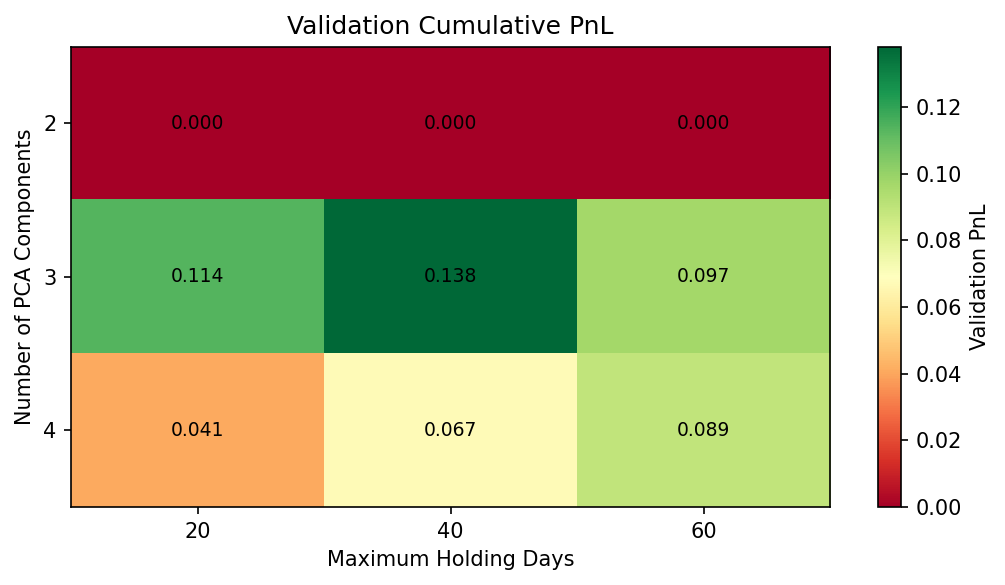

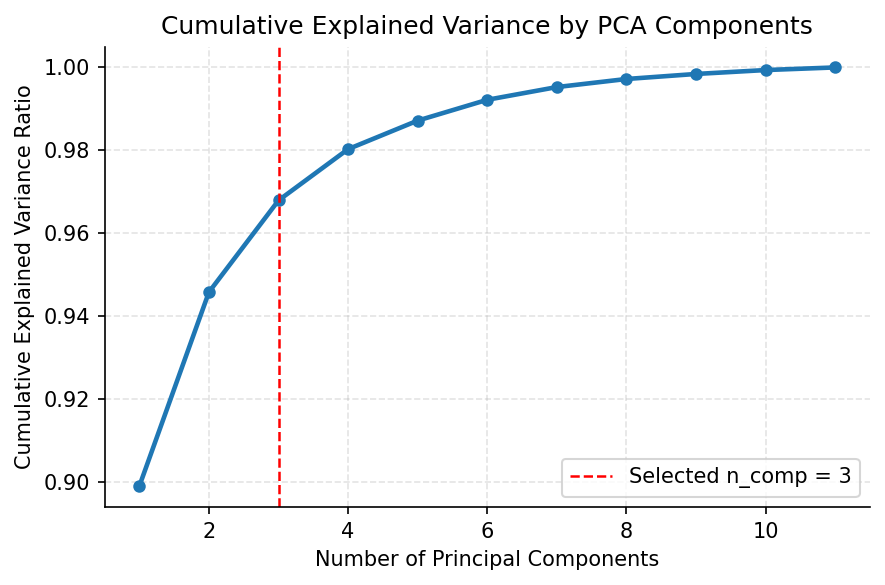

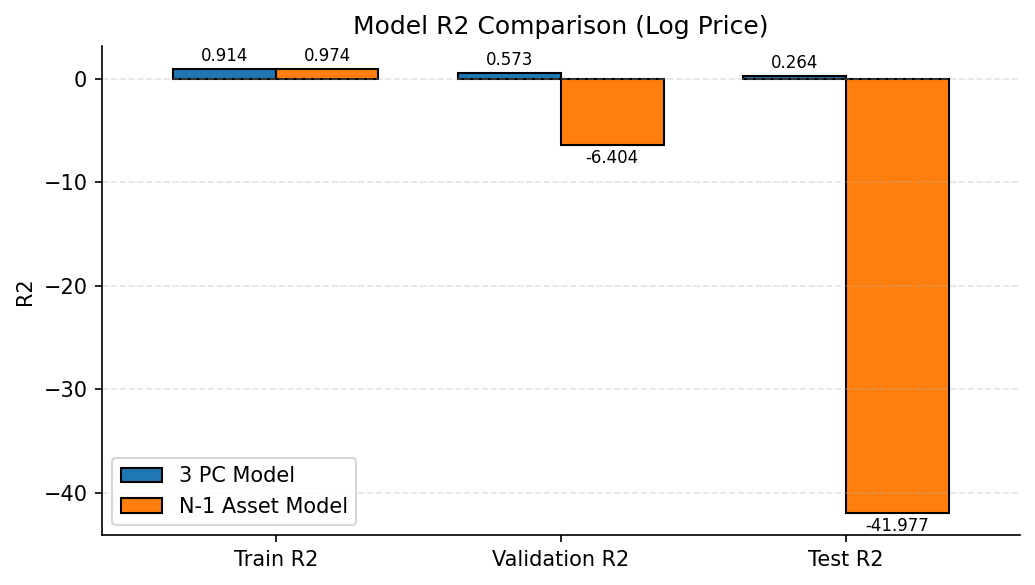

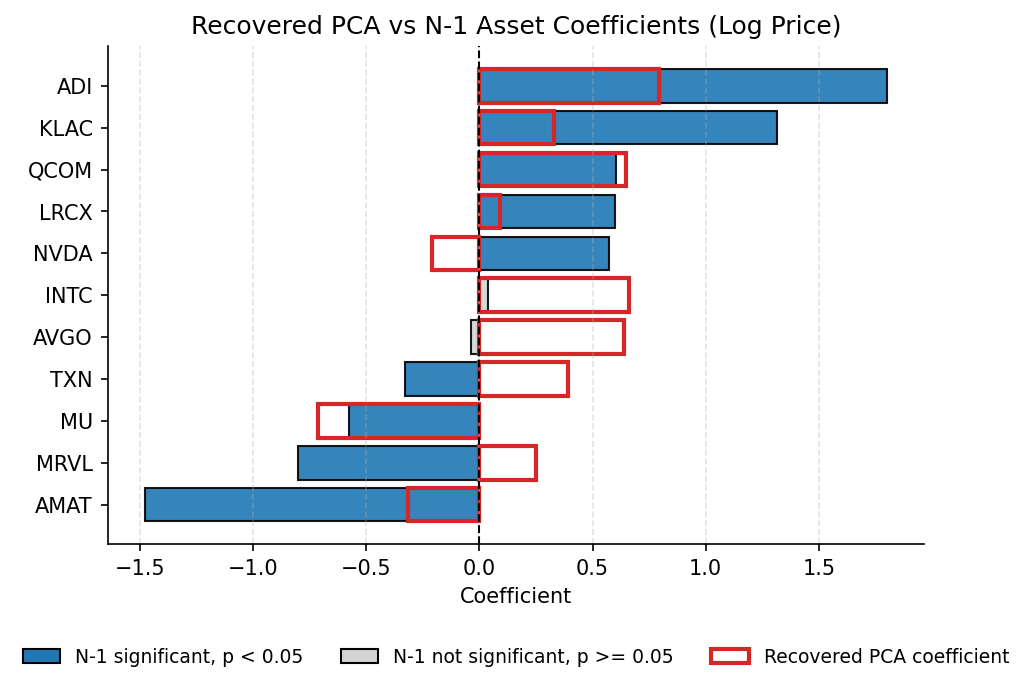

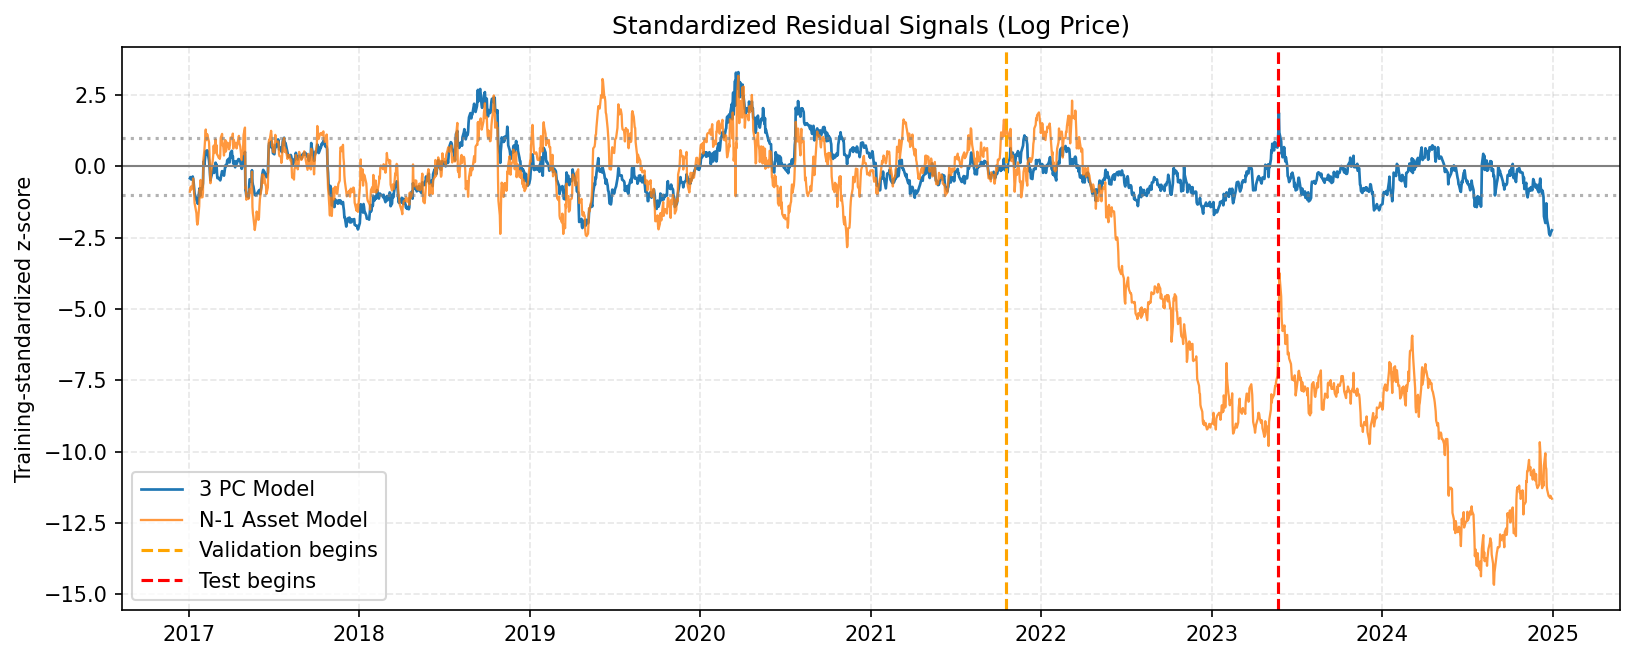

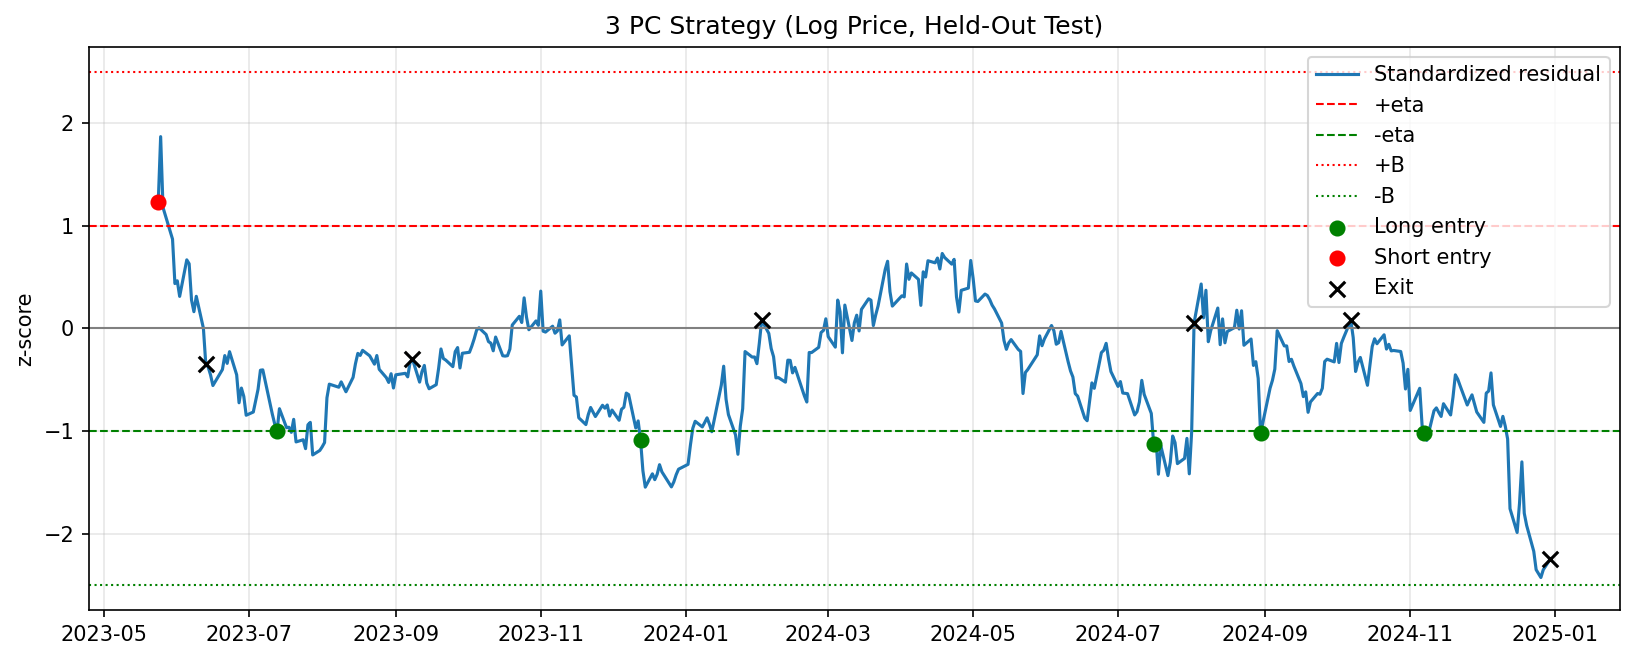

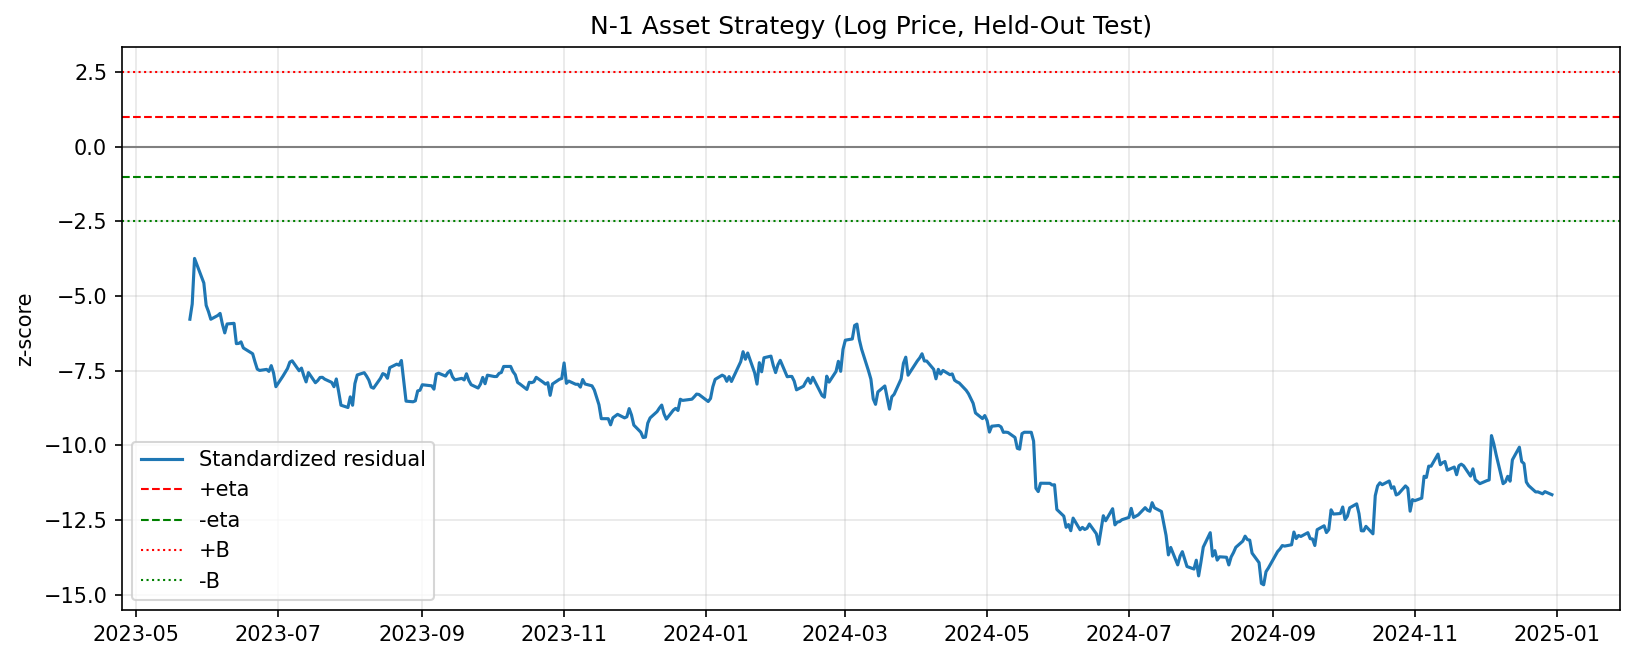

In [8]:
results_log = run_automatic_pipeline(
    stock_ls=stock_ls,
    start=start,
    end=end,
    raw_prices=raw_prices,
    split_ratio=split_ratio,
    val_ratio=val_ratio,
    target_idx=target_idx,
    n_comp_grid=n_comp_grid,
    max_holding_grid=max_holding_grid,
    eta=eta,
    B=B,
    log=True,
    show_plots=True,
)

### Selected Hyperparameters and Final Test Trades


In [9]:
print(results_log["best_params"])
results_log["test_pca_trades"].round(4)

{'n_comp': 3, 'max_holding': 40}


,entry_date,entry_z,side,direction,weights,pnl,holding_days,exit_date,exit_z,exit_reason,cum_pnl
0,2023-05-24,1.2373,-1,short,AMD -0.165488 NVDA -0.034523 INTC 0.10...,0.0615,13,2023-06-13,-0.3475,cross_zero,0.0615
1,2023-07-13,-1.0012,1,long,AMD 0.165488 NVDA 0.034523 INTC -0.10...,0.0257,40,2023-09-08,-0.2987,max_holding,0.0872
2,2023-12-13,-1.0858,1,long,AMD 0.165488 NVDA 0.034523 INTC -0.10...,0.0440,34,2024-02-02,0.0809,cross_zero,0.1313
3,2024-07-16,-1.1235,1,long,AMD 0.165488 NVDA 0.034523 INTC -0.10...,0.0380,13,2024-08-02,0.0524,cross_zero,0.1693
4,2024-08-30,-1.0241,1,long,AMD 0.165488 NVDA 0.034523 INTC -0.10...,0.0411,25,2024-10-07,0.0791,cross_zero,0.2104
5,2024-11-07,-1.0240,1,long,AMD 0.165488 NVDA 0.034523 INTC -0.10...,-0.0511,35,2024-12-30,-2.2471,end_of_period,0.1593


## Run the Automatic Pipeline: Raw Price

Specification: Raw Price
Target: AMD
Selected hyperparameters: {'n_comp': 2, 'max_holding': 20}

Data split:


,segment,start,end,observations
0,Train,2017-01-03,2021-10-15,1206
1,Validation,2021-10-18,2023-05-23,402
2,Test,2023-05-24,2024-12-30,403



Top validation configurations:


,n_comp,max_holding,validation_pnl,validation_trades,validation_win_rate
0,2,20,0.0167,5,0.6000
1,2,40,0.0109,5,0.6000
2,3,20,0.0106,7,0.5714
3,3,40,0.0016,7,0.5714
4,3,60,0.0016,7,0.5714
5,4,20,-0.0078,5,0.4000
6,4,40,-0.0210,5,0.4000
7,4,60,-0.0210,5,0.4000
8,2,60,-0.0307,5,0.6000



Model R2:


,2 PC Model,N-1 Asset Model
Train R2,0.8814,0.9811
Validation R2,0.6505,-1.0015
Test R2,-9.0533,-101.0694



Final held-out test performance:


,2 PC Strategy,N-1 Asset Strategy
Number of trades,2.0000,0.0
Cumulative PnL,-0.0958,0.0
Average PnL,-0.0479,NaN
Win rate,0.0000,NaN
Maximum trade PnL,-0.0395,NaN
Minimum trade PnL,-0.0564,NaN
Maximum drawdown,-0.0958,NaN


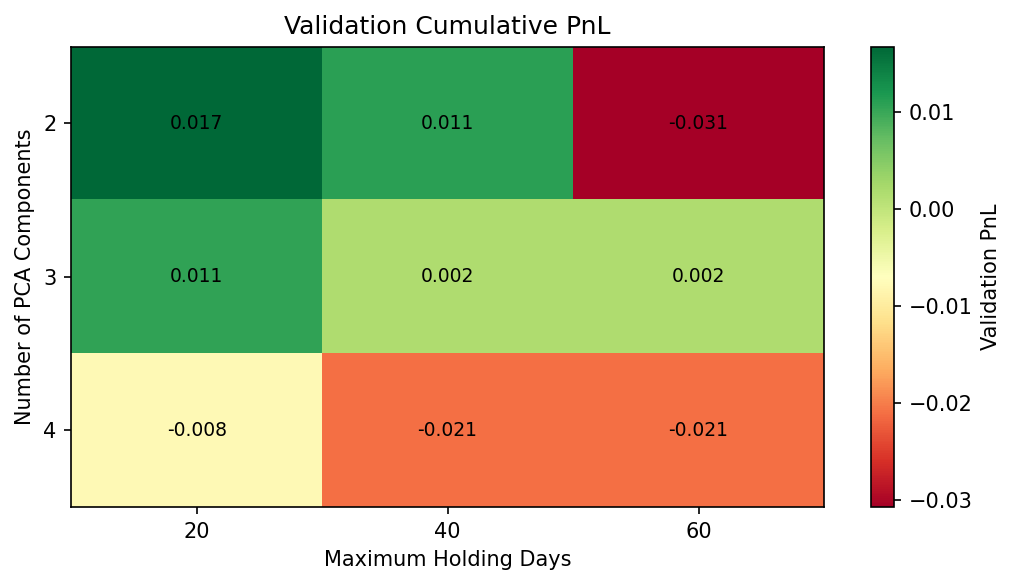

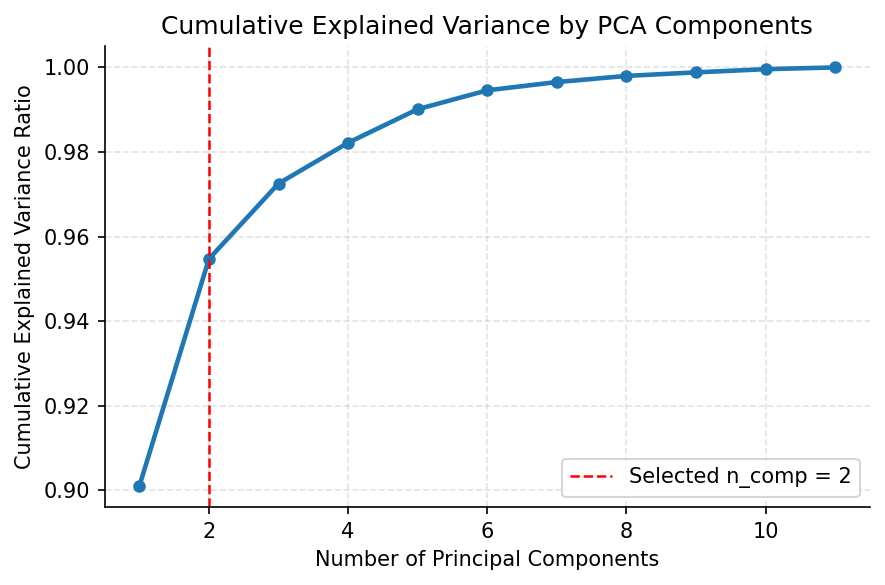

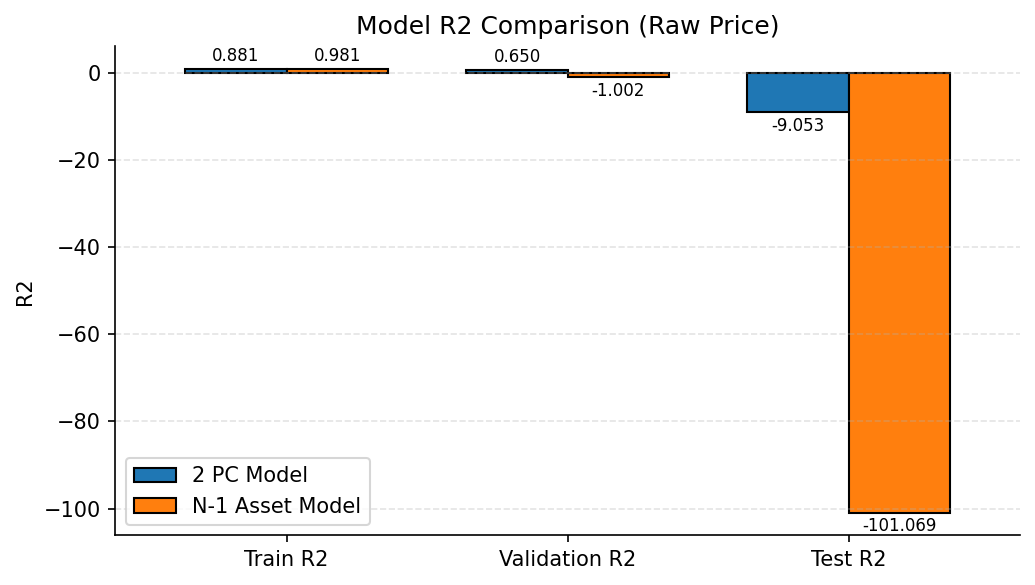

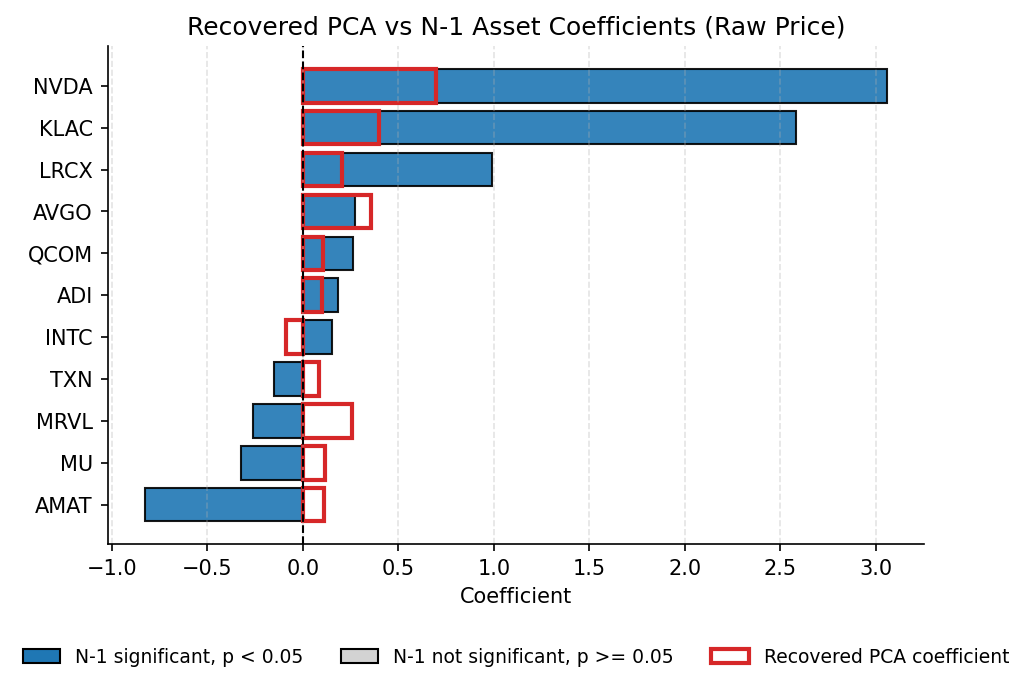

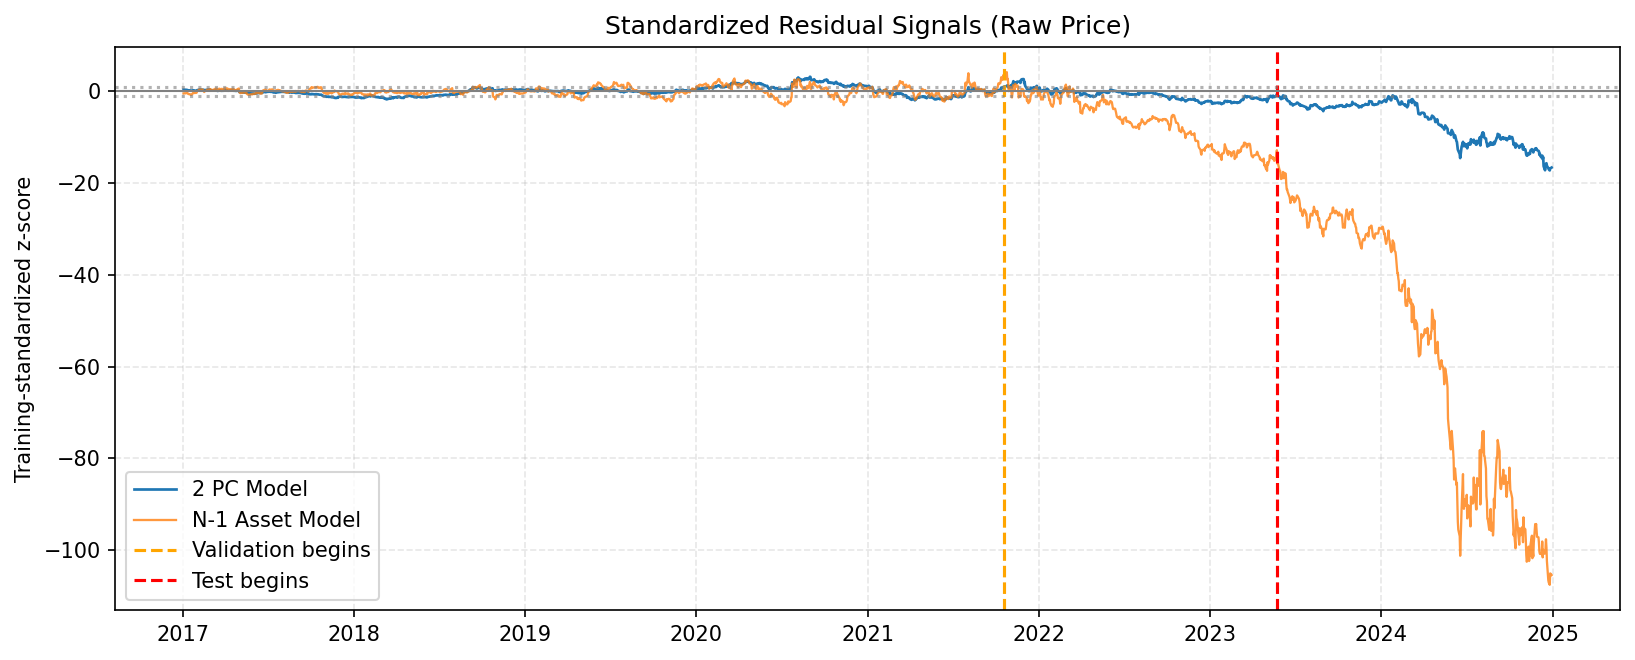

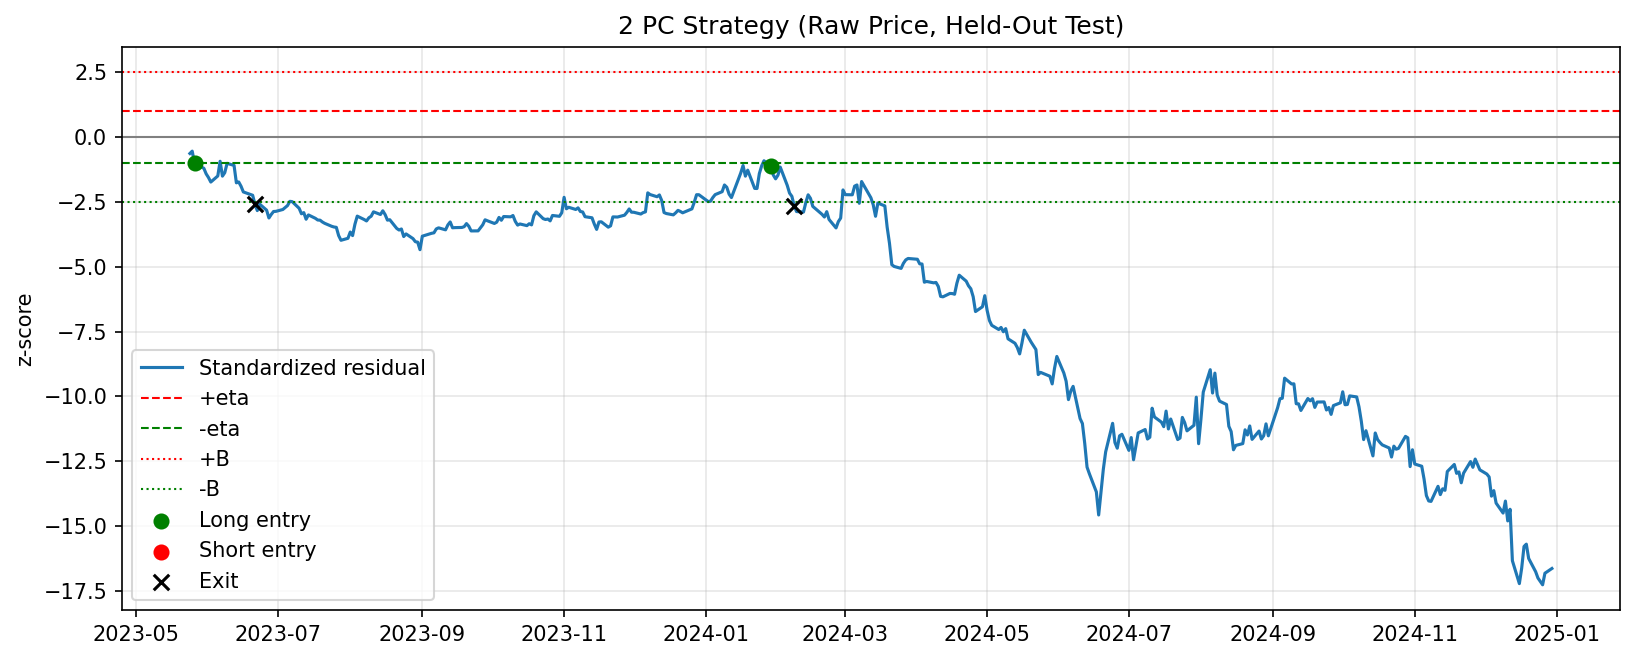

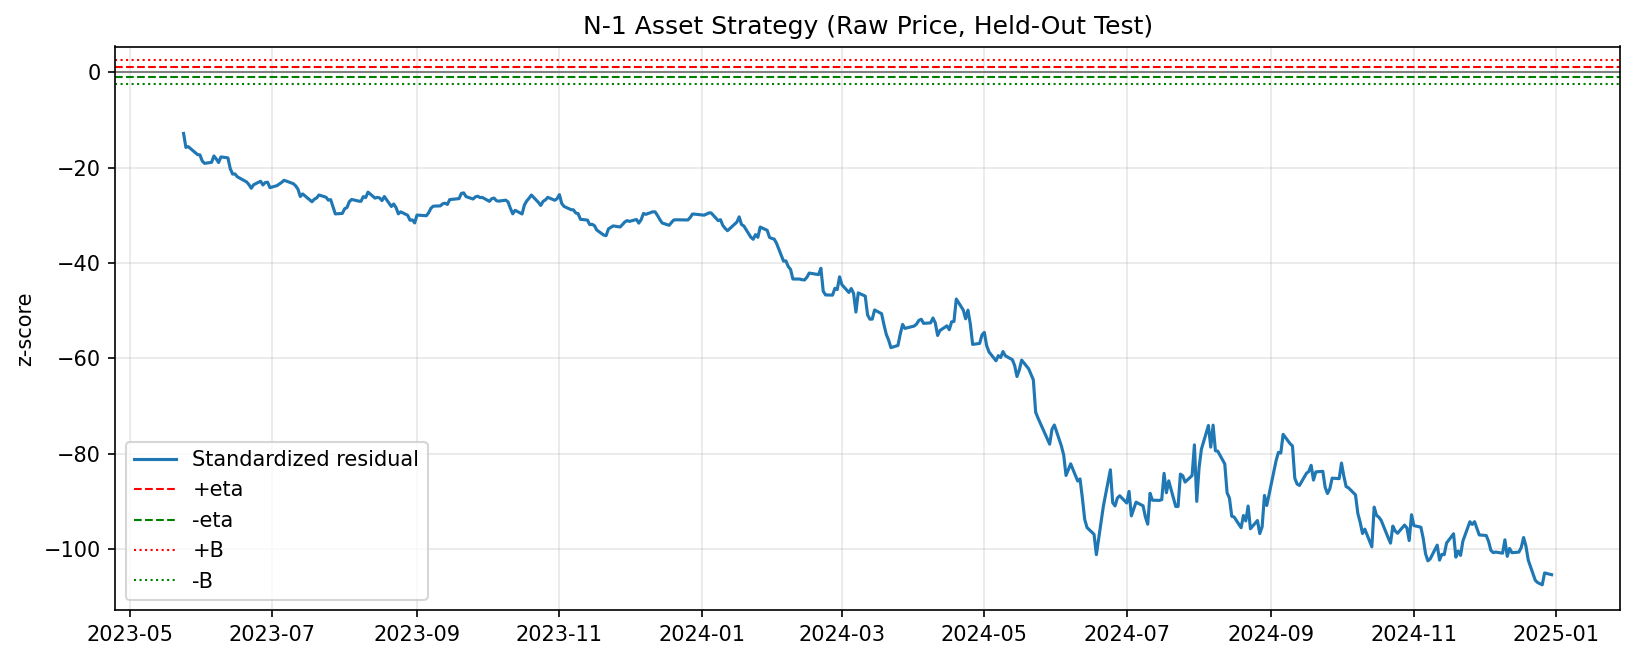

In [10]:
results_raw = run_automatic_pipeline(
    stock_ls=stock_ls,
    start=start,
    end=end,
    raw_prices=raw_prices,
    split_ratio=split_ratio,
    val_ratio=val_ratio,
    target_idx=target_idx,
    n_comp_grid=n_comp_grid,
    max_holding_grid=max_holding_grid,
    eta=eta,
    B=B,
    log=False,
    show_plots=True,
)

### Selected Hyperparameters and Final Test Trades

In [11]:
print(results_raw["best_params"])
results_raw["test_pca_trades"].round(4)

{'n_comp': 2, 'max_holding': 20}


,entry_date,entry_z,side,direction,weights,pnl,holding_days,exit_date,exit_z,exit_reason,cum_pnl
0,2023-05-26,-1.0157,1,long,AMD 0.429408 NVDA -0.091638 INTC 0.00...,-0.0564,16,2023-06-21,-2.5927,stop_loss,-0.0564
1,2024-01-29,-1.1243,1,long,AMD 0.443299 NVDA -0.108417 INTC 0.00...,-0.0395,8,2024-02-08,-2.6506,stop_loss,-0.0958


## Log Price vs Raw Price Comparison\n

In [12]:
price_specification_comparison = compare_price_specifications(
    results_log, results_raw
)
price_specification_comparison.round(4)

,Selected n_comp,Selected max_holding,Best validation PnL,Validation R2,Test R2,Test trades,Test cumulative PnL,Test win rate,Test maximum drawdown
Specification,,,,,,,,,
Log Price,3,40,0.1381,0.5731,0.2642,6.0,0.1593,0.8333,-0.0511
Raw Price,2,20,0.0167,0.6505,-9.0533,2.0,-0.0958,0.0000,-0.0958
